In [29]:
import os
import json
import torch
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from model import GrokkingSetup
import plotly.express as px

# 64 Embedding Dimensions

In [30]:
def GetModelFromConfig(path):
    config_path = os.path.join(path, "config.json")
    with open(config_path, "r") as f:
        config = json.load(f)
        
    model = GrokkingSetup(
        d_model=config["d_model"], 
        voc_size=config["voc_size"],
        pos_encoding=config.get("pos_encoding", 4), 
        d_k=config["d_k"], 
        d_v=config["d_v"], 
        n_layers=config["n_layers"]
    )
    
    return model

In [31]:
def plot_input_only_pca(model, N):
    input_offset = N
    str_shift = 0.001

    weights = model.tokens_embed.weight.detach().cpu().numpy()
    
    input_indices = list(range(-N + input_offset, N + input_offset + 1))
    input_weights = weights[input_indices]

    embeds_2d = PCA(n_components=2).fit_transform(input_weights)
    
    plt.figure(figsize=(8, 8))
    plt.scatter(embeds_2d[:, 0], embeds_2d[:, 1], c='red', s=100)
    
    for i, val in enumerate(range(-N, N)):
        plt.text(embeds_2d[i, 0] + str_shift, embeds_2d[i, 1] + str_shift, str(val), fontsize=12, weight='bold')
        
    plt.title(f"Zoom na strukturę liczb wejściowych (indeksy 0-{2*N})")
    plt.grid(True, alpha=0.3)
    plt.show()

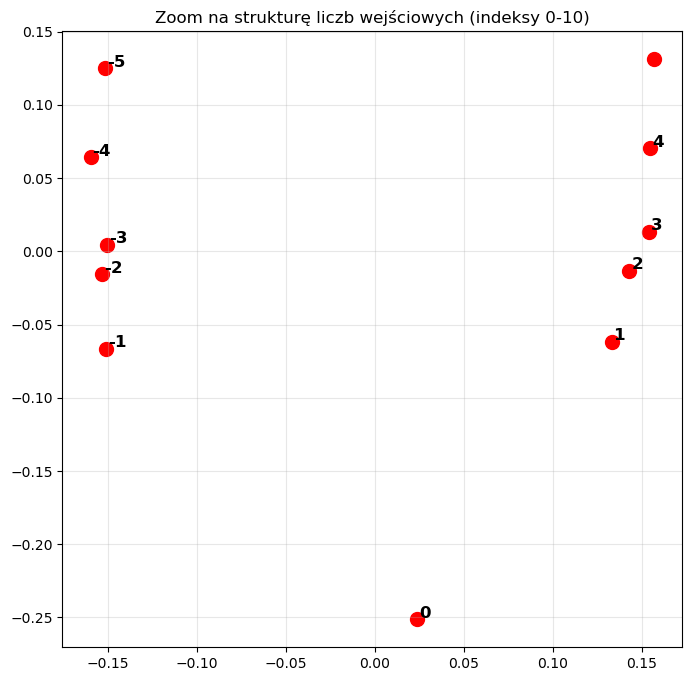

In [52]:
path = r"/home/aleczo/Documents/Temp/Research/grokking/research/ComplexNumbers/experiments/run_L2_D128_20260510_084329"

model = GetModelFromConfig(path)

model_path = r"/home/aleczo/Documents/Temp/Research/grokking/research/ComplexNumbers/experiments/run_L2_D128_20260510_084329/checkpoints/model_epoch_19000.pt"

model.load_state_dict(torch.load(model_path))

plot_input_only_pca(model, 5)

In [33]:
def plot_input_pca_3d_plotly(model, N):
    weights = model.tokens_embed.weight.detach().cpu().numpy()

    input_offset = N    
    input_values = list(range(-N, N + 1))
    input_indices = [val + input_offset for val in input_values]
    
    if max(input_indices) >= weights.shape[0] or min(input_indices) < 0:
        return

    active_weights = weights[input_indices]
    
    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(active_weights)
    
    df = pd.DataFrame(embeds_3d, columns=['PCA1', 'PCA2', 'PCA3'])
    df['label'] = input_values

    fig = px.scatter_3d(
        df, 
        x='PCA1', 
        y='PCA2', 
        z='PCA3',
        color='label',
        text='label',
        color_continuous_scale='Portland',
        title=f"3D PCA: Input Tokens Structure (N={N}, offset={input_offset})",
        labels={'label': 'Wartość wejściowa'},
        opacity=0.8
    )

    fig.update_traces(
        marker=dict(size=6, line=dict(width=1, color='Black')),
        textposition='top center'
    )

    fig.update_layout(
        margin=dict(l=0, r=0, b=0, t=40),
        scene=dict(
            xaxis_title='PCA 1',
            yaxis_title='PCA 2',
            zaxis_title='PCA 3'
        )
    )
    
    fig.show()



In [34]:
plot_input_pca_3d_plotly(model, N=5)

In [35]:
def plot_real_output_pca(model, N):
    weights = model.unembed_re.weight.detach().cpu().numpy()
    
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]
    

    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(active_weights)
    
    plt.figure(figsize=(12, 10))
    scatter = plt.scatter(
        embeds_2d[:, 0], 
        embeds_2d[:, 1], 
        c=labels, 
        cmap="coolwarm", 
        s=80, 
        edgecolor='black',
        alpha=0.8
    )
    
    plt.colorbar(scatter, label='Wartość wynikowa (Real)')
    

    for i, label in enumerate(labels):
        if label % 1 == 0: 
            plt.text(
                embeds_2d[i, 0] + 0.002, 
                embeds_2d[i, 1] + 0.002, 
                str(label), 
                fontsize=9, weight='bold'
            )
            
    plt.title(f"Struktura wyjść modelu (Unembed Real) dla N={N}")
    plt.grid(True, alpha=0.2)
    plt.show()

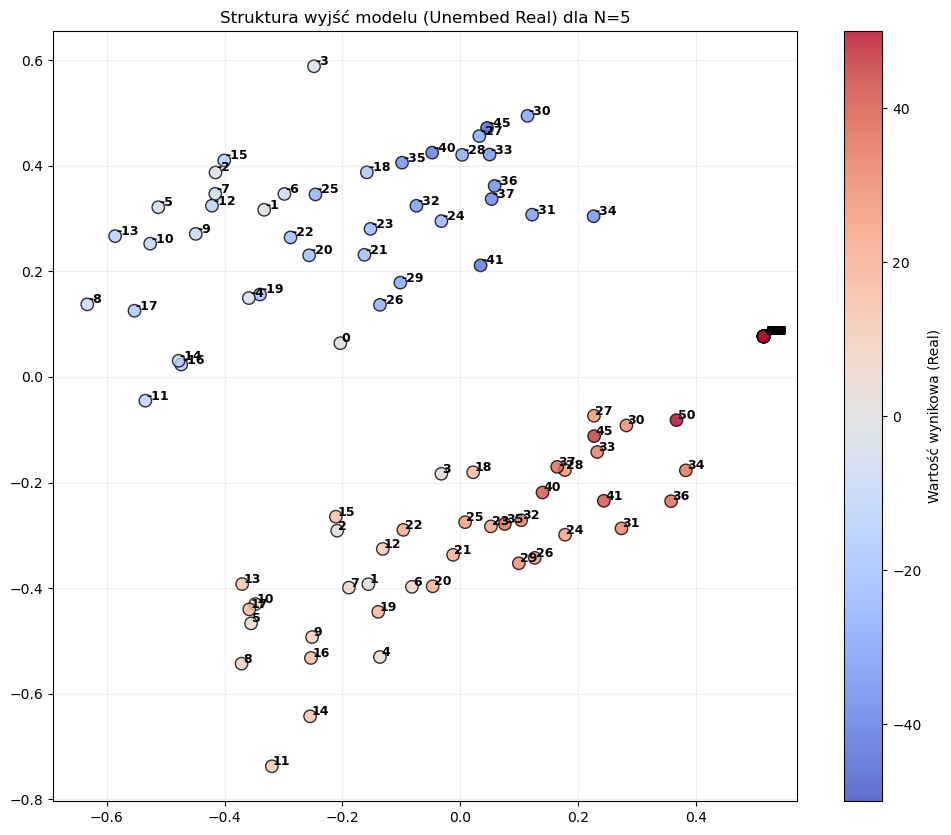

In [36]:
plot_real_output_pca(model, N=5)

In [37]:
def plot_imag_output_pca(model, N=5):
    weights = model.unembed_im.weight.detach().cpu().numpy()
    
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)
            
    active_weights = weights[active_indices]
    
    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(active_weights)
    
    plt.figure(figsize=(12, 10))
    scatter = plt.scatter(
        embeds_2d[:, 0], 
        embeds_2d[:, 1], 
        c=labels, 
        cmap="coolwarm",
        s=80, 
        edgecolor='black',
        alpha=0.8
    )
    
    plt.colorbar(scatter, label='Wartość wynikowa (Imaginary)')
    

    for i, label in enumerate(labels):
        if label % 10 == 0:
            plt.text(
                embeds_2d[i, 0] + 0.002, 
                embeds_2d[i, 1] + 0.002, 
                str(label), 
                fontsize=9, weight='bold'
            )
            
    plt.title(f"Struktura wyjść modelu (Unembed Imaginary) dla N={N}")
    plt.grid(True, alpha=0.2)
    plt.show()

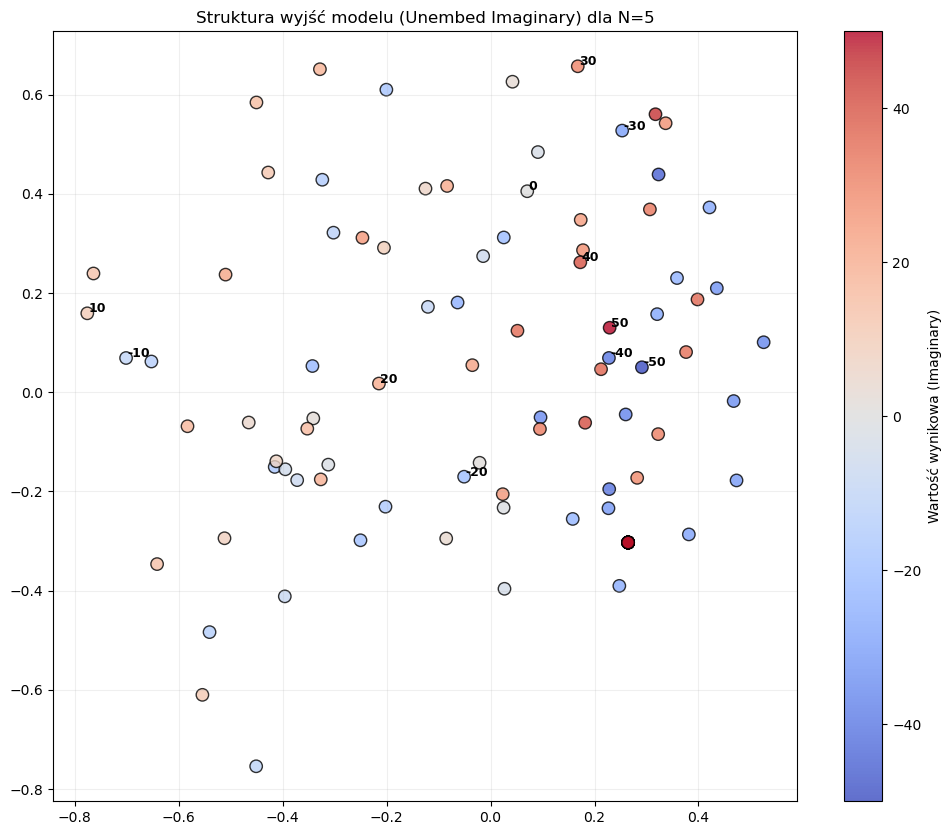

In [38]:
plot_imag_output_pca(model, N=5)

In [39]:
def plot_real_output_pca_3d(model, N):
    output_offset = 2 * N * N
    weights = model.unembed_re.weight.detach().cpu().numpy()
    
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)
            
    active_weights = weights[active_indices]

    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(active_weights)
    
    df = pd.DataFrame(embeds_3d, columns=['PCA1', 'PCA2', 'PCA3'])
    df['label'] = labels
    df['abs_val'] = df['label'].abs() 

    fig = px.scatter_3d(
        df, 
        x='PCA1', 
        y='PCA2', 
        z='PCA3',
        color='label',
        text='label',
        color_continuous_scale='Spectral',
        title=f"3D PCA: Struktura Unembed Real (N={N}, offset={output_offset})",
        labels={'label': 'Wartość'},
        opacity=0.8
    )


    fig.update_traces(
        marker=dict(size=5, line=dict(width=1, color='Black')),
        textposition='top center'
    )

    fig.update_layout(
        margin=dict(l=0, r=0, b=0, t=40),
        scene=dict(
            xaxis_title='PCA 1',
            yaxis_title='PCA 2',
            zaxis_title='PCA 3'
        )
    )
    
    fig.show()

In [40]:
plot_real_output_pca_3d(model, N=5)

In [41]:
def plot_output_im_pca_3d_plotly(model, N):
    weights = model.unembed_im.weight.detach().cpu().numpy()
    
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)
            
    active_weights = weights[active_indices]

    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(active_weights)
    
    df = pd.DataFrame(embeds_3d, columns=['PCA1', 'PCA2', 'PCA3'])
    df['label'] = labels

    fig = px.scatter_3d(
        df, 
        x='PCA1', 
        y='PCA2', 
        z='PCA3',
        color='label',
        text='label',
        color_continuous_scale='Viridis',
        title=f"3D PCA: Struktura Unembed Imaginary (N={N}, offset={output_offset})",
        labels={'label': 'Wartość urojona'},
        opacity=0.8
    )

    fig.update_traces(
        marker=dict(size=5, line=dict(width=1, color='Black')),
        textposition='top center'
    )

    fig.update_layout(
        margin=dict(l=0, r=0, b=0, t=40),
        scene=dict(
            xaxis_title='PCA 1',
            yaxis_title='PCA 2',
            zaxis_title='PCA 3'
        )
    )
    
    fig.show()

In [42]:
plot_output_im_pca_3d_plotly(model, N=5)

In [43]:
import numpy as np

def plot_input_pca_3d_polar(model, N=6, input_offset=6):
    weights = model.tokens_embed.weight.detach().cpu().numpy()
    
    input_values = list(range(-N, N + 1))
    input_indices = [val + input_offset for val in input_values]
    
    active_weights = weights[input_indices]
    
    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(active_weights)
    
    df = pd.DataFrame(embeds_3d, columns=['PCA1', 'PCA2', 'PCA3'])
    df['label'] = input_values
    
    # Obliczamy fazę i moduł dla wizualizacji (zakładając wejście jako czysto realne lub urojone)
    # Tu możesz zaszaleć i podać modelowi pary (a, b) i zobaczyć jak je układa
    
    fig = px.scatter_3d(
        df, x='PCA1', y='PCA2', z='PCA3',
        color='label', text='label',
        color_continuous_scale='Twilight'
    )
    fig.show()

In [44]:
def plot_joint_complex_pca_3d(model, N=6):
    w_re = model.unembed_re.weight.detach().cpu().numpy()
    w_im = model.unembed_im.weight.detach().cpu().numpy()

    output_offset = 2 * N * N
    
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < w_re.shape[0]:
            active_indices.append(idx)
            labels.append(val)
            
    re_weights = w_re[active_indices]
    im_weights = w_im[active_indices]
    
    joint_weights = np.concatenate([re_weights, im_weights], axis=1)

    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(joint_weights)
    
    df = pd.DataFrame(embeds_3d, columns=['PCA1', 'PCA2', 'PCA3'])
    df['label'] = labels
    
    fig = px.scatter_3d(
        df, x='PCA1', y='PCA2', z='PCA3',
        color='label', text='label',
        color_continuous_scale='RdBu_r',
        title=f"Joint 3D PCA: Real + Imaginary Weights (N={N})",
        labels={'label': 'Wartość (n)'},
        opacity=0.8
    )

    fig.update_traces(
        marker=dict(size=5, line=dict(width=1, color='Black')),
        textposition='top center'
    )

    fig.update_layout(
        margin=dict(l=0, r=0, b=0, t=40)
    )
    
    fig.show()

plot_joint_complex_pca_3d(model, N=5)

In [45]:
plot_input_pca_3d_polar(model)

In [46]:
def plot_output_complex_polar_pca_3d(model, N=6):
    w_re = model.unembed_re.weight.detach().cpu().numpy()
    w_im = model.unembed_im.weight.detach().cpu().numpy()
    
    min_val, max_val = -2 * N * N, 2 * N * N
    output_offset = 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < w_re.shape[0]:
            active_indices.append(idx)
            labels.append(val)
            
    re_weights = w_re[active_indices]
    im_weights = w_im[active_indices]
    
    joint_weights = np.concatenate([re_weights, im_weights], axis=1)

    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(joint_weights)
    
    df = pd.DataFrame(embeds_3d, columns=['PCA1', 'PCA2', 'PCA3'])
    df['label'] = labels
    df['abs_label'] = np.abs(df['label'])
    
    fig = px.scatter_3d(
        df, 
        x='PCA1', 
        y='PCA2', 
        z='PCA3',
        color='label',
        text='label',
        color_continuous_scale='Picnic',
        title=f"3D PCA: Joint Output Structure (Re+Im) | N={N}",
        labels={'label': 'Wartość składowej'},
        opacity=0.8
    )

    fig.update_traces(
        marker=dict(size=5, line=dict(width=1, color='Black')),
        textposition='top center'
    )

    fig.update_layout(
        margin=dict(l=0, r=0, b=0, t=40),
        scene=dict(
            xaxis_title='V1 (Global Structure)',
            yaxis_title='V2 (Periodic)',
            zaxis_title='V3 (Magnitude/Sign)'
        )
    )
    
    fig.show()

plot_output_complex_polar_pca_3d(model, N=5)


In [47]:
def plot_output_joint_pca_2d(model, N=6):
    w_re = model.unembed_re.weight.detach().cpu().numpy()
    w_im = model.unembed_im.weight.detach().cpu().numpy()

    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < w_re.shape[0]:
            active_indices.append(idx)
            labels.append(val)
            
    re_weights = w_re[active_indices]
    im_weights = w_im[active_indices]
    
    joint_weights = np.concatenate([re_weights, im_weights], axis=1)

    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(joint_weights)
    
    df = pd.DataFrame(embeds_2d, columns=['PCA1', 'PCA2'])
    df['label'] = labels
    df['magnitude'] = np.abs(df['label'])

    fig = px.scatter(
        df, 
        x='PCA1', 
        y='PCA2', 
        color='label',
        text='label',
        color_continuous_scale='Picnic',
        title=f"2D PCA: Joint Output Structure (Re+Im) | N={N}",
        template="plotly_dark"
    )

    fig.update_traces(
        marker=dict(size=12, line=dict(width=1, color='white')),
        textposition='top center'
    )

    fig.show()

plot_output_joint_pca_2d(model, N=5)

# 32 Embedding Dimensions

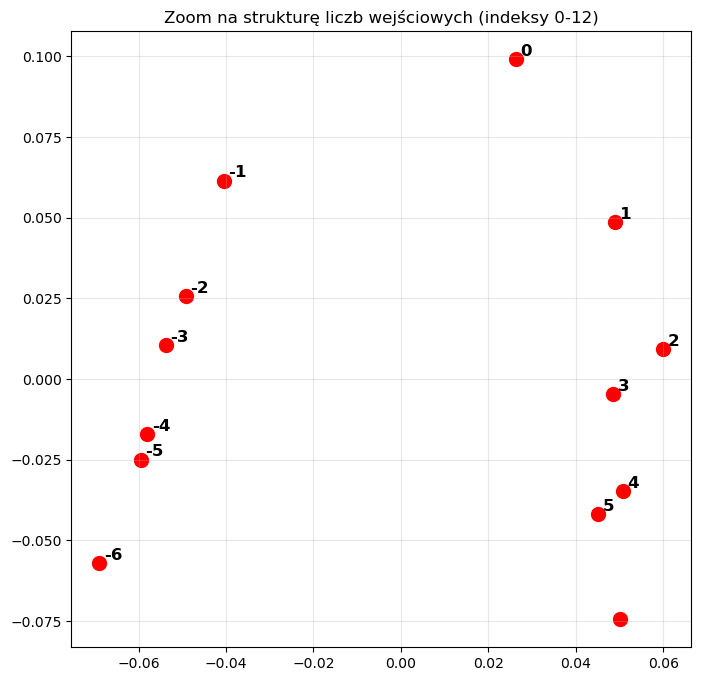

In [48]:
path = r"/home/aleczo/Documents/Temp/Research/grokking/research/ComplexNumbers/experiments/run_L2_D32_20260510_224142"

model = GetModelFromConfig(path)

model_path = r"/home/aleczo/Documents/Temp/Research/grokking/research/ComplexNumbers/experiments/run_L2_D32_20260510_224142/checkpoints/model_epoch_19000.pt"

model.load_state_dict(torch.load(model_path))

plot_input_only_pca(model, 6)

In [49]:
plot_input_pca_3d_plotly(model, N=6)

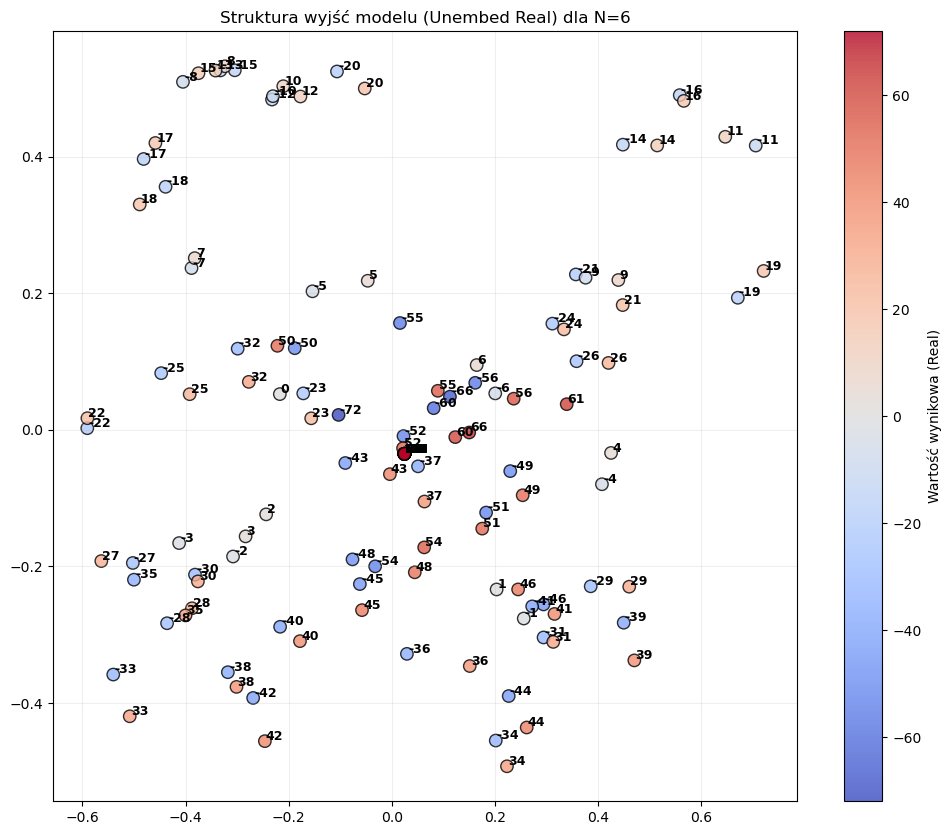

In [50]:
plot_real_output_pca(model, N=6)

In [51]:
plot_real_output_pca_3d(model, N=6)